# YOLOX-Tiny: phone and QA checks

Run all cells in order using the environment from notebook 10. Uses the exported ONNX model on CPU; no CUDA, training, export, or dataset preparation is needed.

This checks all images in training/data/raw/{driving_licence,passport,none}, with a separate summary for the three new QA images. Folder names supply expected document types. Edit QA_FILES below when adding more QA images; it is an explicit list, not inferred from timestamps. The empty raw/qa folder is not scanned because it has no expected class labels.

The confidence threshold and NMS settings come from the model's embedded contract and stay fixed. We report image-level type matches and any detection on a negative image. Positive images may contain extra incorrect boxes even when the top type matches, so every box is shown and labelled. There are no ground-truth boxes: these checks do not establish localisation accuracy or capture quality.

Keep QA documents separate from training. Repeated inspection makes this a development check rather than a blind benchmark. Results and detections remain in notebook memory; originals, checkpoints, calibration, and model files are not changed. Clear notebook outputs before sharing if the images contain personal data.

In [1]:
from pathlib import Path
from collections import Counter
import sys
import time
from html import escape

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, HTML

PROJECT = Path("/home/joe/PycharmProjects/id-capture")
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from id_capture.onnx_detector import (
    OnnxDocumentDetector, CLASS_NAMES, read_bgr, document_result,
)

MODEL = PROJECT / "models/yolox-tiny-retrained.onnx"
RAW = PROJECT / "training/data/raw"
QA_FILES = {
    "driving_licence/driving_licence3.jpg",
    "passport/passport4.jpg",
    "passport/passport5.jpg",
}
EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".webp"}

assert MODEL.is_file(), f"Run notebook 10 first: {MODEL}"
detector = OnnxDocumentDetector(MODEL, providers=["CPUExecutionProvider"])
print("Model:", MODEL)
print("Input size:", detector.size)
print("Saved confidence:", detector.confidence, "| NMS IoU:", detector.nms_iou)
print("Validation targets met:", detector.contract.get("validation_targets_met"))

def show_table(rows):
    if not rows:
        print("No rows.")
        return
    columns = list(rows[0])
    header = "".join(f"<th>{escape(str(c))}</th>" for c in columns)
    body = "".join(
        "<tr>" + "".join(
            f"<td>{escape(str(row[c]))}</td>" for c in columns
        ) + "</tr>" for row in rows
    )
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))


Model: /home/joe/PycharmProjects/id-capture/models/yolox-tiny-retrained.onnx
Input size: 416
Saved confidence: 0.2 | NMS IoU: 0.65
Validation targets met: False


In [2]:
samples = []
for expected in (*CLASS_NAMES, "none"):
    folder = RAW / expected
    if not folder.is_dir():
        continue
    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in EXTENSIONS:
            key = path.relative_to(RAW).as_posix()
            samples.append({
                "path": path, "key": key, "expected": expected,
                "group": "New QA" if key in QA_FILES else "Existing",
            })

assert samples, f"No supported images found under {RAW}"
found = {sample["key"] for sample in samples}
assert not (QA_FILES - found), f"Missing QA images: {sorted(QA_FILES - found)}"
print("Images:", len(samples))
print("Counts:", dict(Counter((s["group"], s["expected"]) for s in samples)))
print("QA images:", sorted(QA_FILES))


Images: 12
Counts: {('Existing', 'driving_licence'): 2, ('New QA', 'driving_licence'): 1, ('Existing', 'passport'): 3, ('New QA', 'passport'): 2, ('Existing', 'none'): 4}
QA images: ['driving_licence/driving_licence3.jpg', 'passport/passport4.jpg', 'passport/passport5.jpg']


In [3]:
# One image at a time; only compact detections are retained.
results = []
detections_by_key = {}
started = time.perf_counter()
for index, sample in enumerate(samples, 1):
    image = read_bgr(sample["path"])
    detections = detector.predict_bgr(image)
    result = document_result(detections)
    predicted = result["document_type"]
    expected = sample["expected"]
    detections_by_key[sample["key"]] = detections
    wrong_class_box = (
        expected != "none"
        and any(CLASS_NAMES[int(d[5])] != expected for d in detections)
    )
    results.append({
        "Photo": sample["key"],
        "Group": sample["group"],
        "Expected": expected,
        "Predicted": predicted,
        "Confidence": (
            f'{result["detection_confidence"]:.1%}'
            if result["detection_confidence"] is not None else "N/A"
        ),
        "Type match": expected == predicted,
        "Detections": len(detections),
        "Wrong-class box": bool(wrong_class_box),
        "Detection on negative": expected == "none" and len(detections) > 0,
    })
    del image
    print(f'{index}/{len(samples)} | {sample["key"]} -> {predicted}', flush=True)

elapsed = time.perf_counter() - started
print(f"Completed {len(results)} images in {elapsed:.2f}s (CPU check, not a phone benchmark).")
show_table(results)

summary = []
for group in ("All", "New QA", "Existing"):
    selected = [r for r in results if group == "All" or r["Group"] == group]
    if not selected:
        continue
    negatives = [r for r in selected if r["Expected"] == "none"]
    false_positives = sum(r["Detection on negative"] for r in negatives)
    summary.append({
        "Group": group,
        "Images": len(selected),
        "Type matches": f'{sum(r["Type match"] for r in selected)}/{len(selected)}',
        "Missed positive (none)": sum(
            r["Expected"] != "none" and r["Predicted"] == "none" for r in selected
        ),
        "Wrong positive type": sum(
            r["Expected"] != "none"
            and r["Predicted"] not in ("none", r["Expected"]) for r in selected
        ),
        "Negative images with detections": (
            f"{false_positives}/{len(negatives)}" if negatives else "N/A"
        ),
        "Positive images with wrong-class boxes": sum(r["Wrong-class box"] for r in selected),
    })
show_table(summary)

review_rows = [
    r for r in results
    if r["Group"] == "New QA" or not r["Type match"] or r["Wrong-class box"]
]
print("QA and failure review:")
show_table(review_rows)
print("These are small-sample type checks; no bounding-box IoU or quality score is available.")


1/12 | driving_licence/driving_licence1.jpg -> driving_licence
2/12 | driving_licence/driving_licence2.jpg -> driving_licence
3/12 | driving_licence/driving_licence3.jpg -> none
4/12 | passport/passport1.jpg -> passport
5/12 | passport/passport2.jpg -> passport
6/12 | passport/passport3.jpg -> passport
7/12 | passport/passport4.jpg -> none
8/12 | passport/passport5.jpg -> none
9/12 | none/none1.jpg -> none
10/12 | none/none2.jpg -> none
11/12 | none/none3.jpg -> none
12/12 | none/none4.jpg -> none
Completed 12 images in 0.57s (CPU check, not a phone benchmark).


Photo,Group,Expected,Predicted,Confidence,Type match,Detections,Wrong-class box,Detection on negative
driving_licence/driving_licence1.jpg,Existing,driving_licence,driving_licence,97.8%,True,1,False,False
driving_licence/driving_licence2.jpg,Existing,driving_licence,driving_licence,94.5%,True,1,False,False
driving_licence/driving_licence3.jpg,New QA,driving_licence,none,N/A,False,0,False,False
passport/passport1.jpg,Existing,passport,passport,26.7%,True,1,False,False
passport/passport2.jpg,Existing,passport,passport,95.4%,True,1,False,False
passport/passport3.jpg,Existing,passport,passport,77.6%,True,1,False,False
passport/passport4.jpg,New QA,passport,none,N/A,False,0,False,False
passport/passport5.jpg,New QA,passport,none,N/A,False,0,False,False
none/none1.jpg,Existing,none,none,N/A,True,0,False,False
none/none2.jpg,Existing,none,none,N/A,True,0,False,False


Group,Images,Type matches,Missed positive (none),Wrong positive type,Negative images with detections,Positive images with wrong-class boxes
All,12,9/12,3,0,0/4,0
New QA,3,0/3,3,0,N/A,0
Existing,9,9/9,0,0,0/4,0


QA and failure review:


Photo,Group,Expected,Predicted,Confidence,Type match,Detections,Wrong-class box,Detection on negative
driving_licence/driving_licence3.jpg,New QA,driving_licence,none,N/A,False,0,False,False
passport/passport4.jpg,New QA,passport,none,N/A,False,0,False,False
passport/passport5.jpg,New QA,passport,none,N/A,False,0,False,False


These are small-sample type checks; no bounding-box IoU or quality score is available.


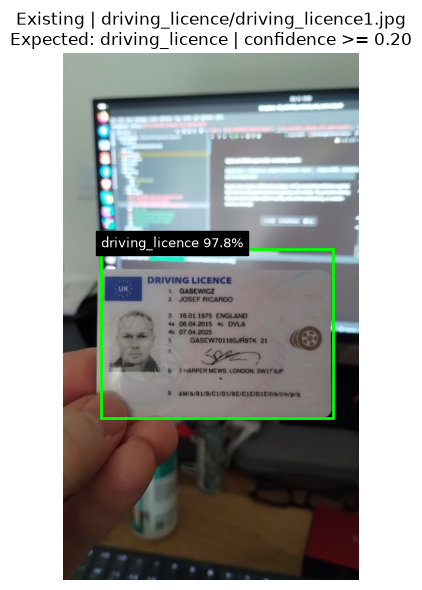

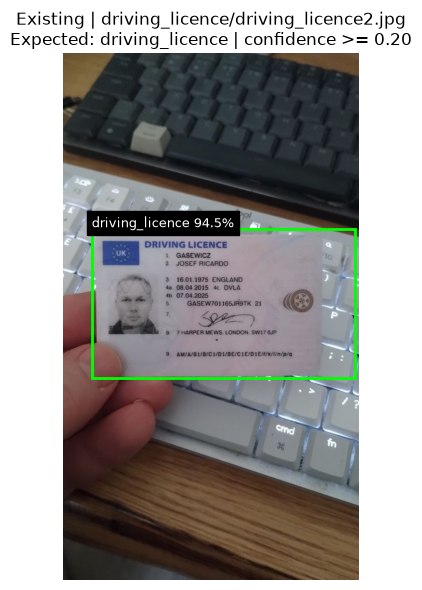

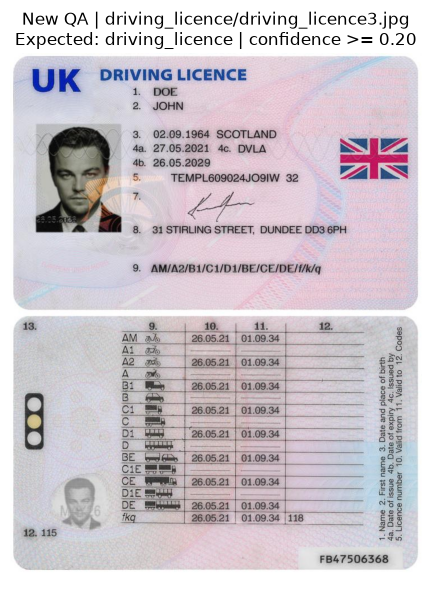

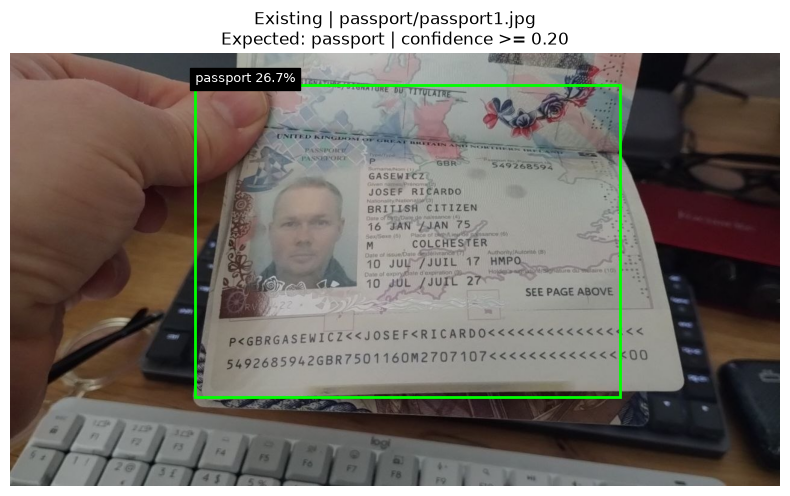

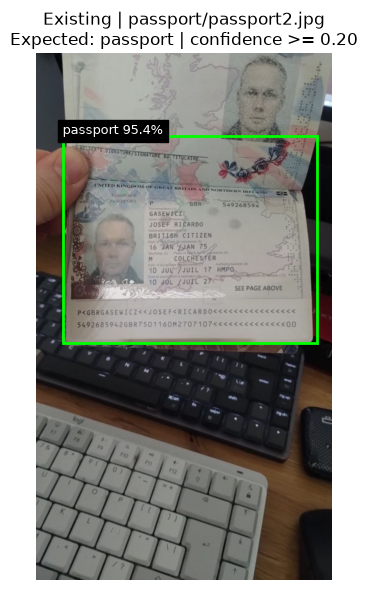

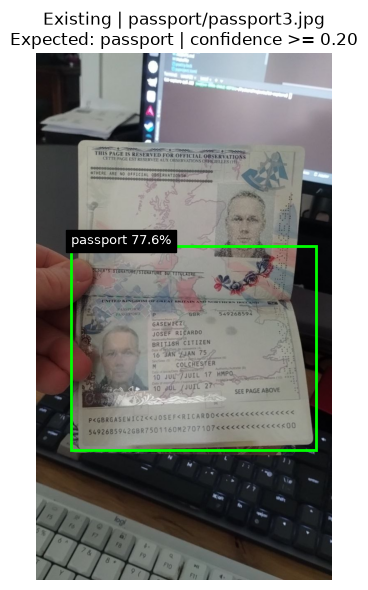

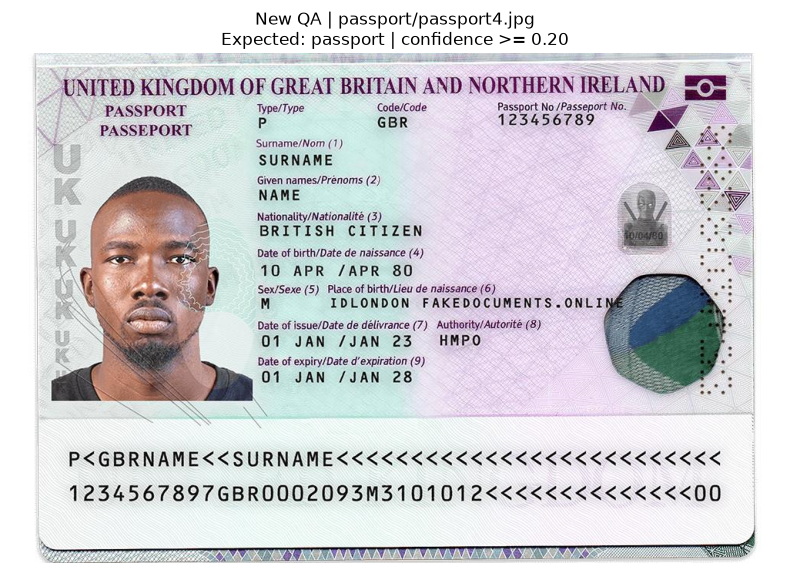

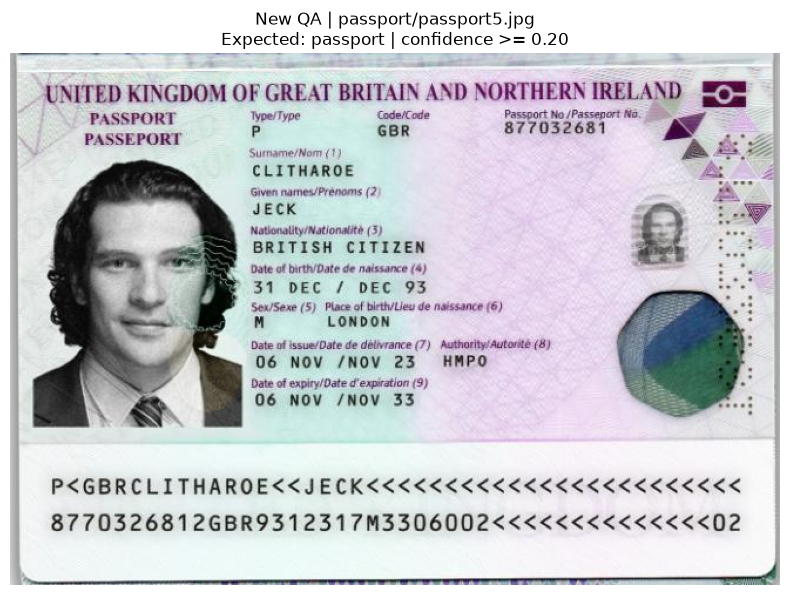

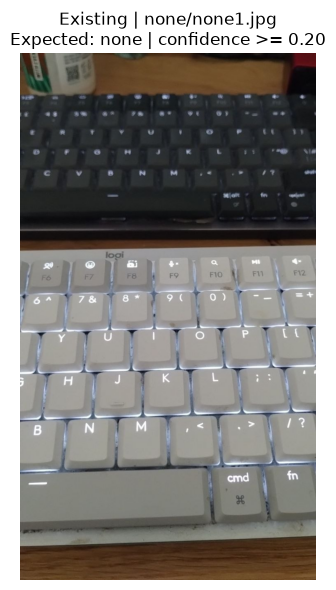

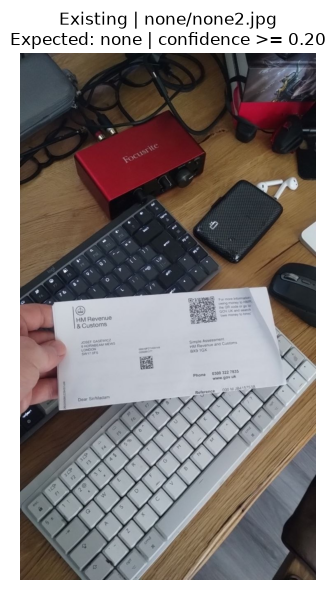

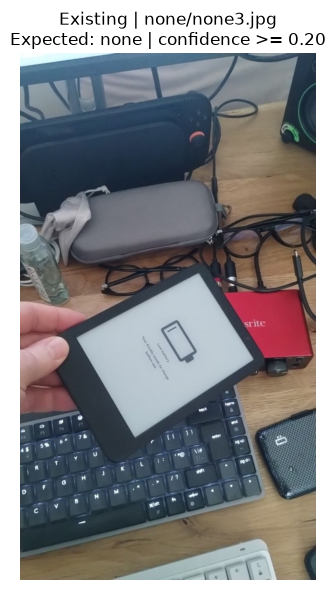

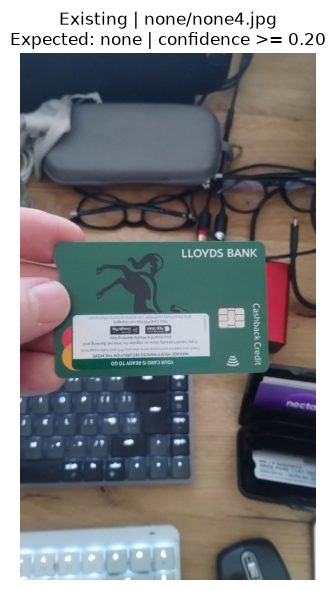

In [4]:
# Display every accepted box, not just the highest-scoring one.
# Set False to show only new QA images and flagged failures.
SHOW_ALL = True
review_keys = {r["Photo"] for r in review_rows}
for sample in samples:
    if not SHOW_ALL and sample["key"] not in review_keys:
        continue
    image = read_bgr(sample["path"])
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(image[:, :, ::-1])
    for x1, y1, x2, y2, score, class_id in detections_by_key[sample["key"]]:
        label = CLASS_NAMES[int(class_id)]
        color = "lime" if label == sample["expected"] else "red"
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor=color, linewidth=2,
        ))
        ax.text(
            x1, max(0, y1 - 5), f"{label} {score:.1%}",
            color="white", backgroundcolor="black", fontsize=9,
        )
    ax.set_title(
        f'{sample["group"]} | {sample["key"]}\n'
        f'Expected: {sample["expected"]} | confidence >= {detector.confidence:.2f}'
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    del image


## Review before another training run

- Inspect whether all document edges are enclosed and whether a box covers the document rather than the background or an unrelated object.
- A correct top type with extra wrong-class boxes still needs investigation.
- Keep the saved threshold for this QA check. Select any future threshold changes on validation data, not these photos.
- Prioritise additional independent UK captures and negatives matching observed false detections. Three new images alone are not enough to measure generalisation.
- New training positives need box annotations and explicit inclusion in the prepared training data. Adding images to raw does not update weights.
- Keep all captures of a physical document in one split. If a QA document is moved into training, it must stop serving as independent evaluation.
- After any training change, rerun validation calibration and development testing in notebook 09, then export/parity checks in notebook 10 and these QA checks. Record regressions as well as improvements.

This notebook was created without executing inference; run it to generate current results.

## Review false positives on negative validation images

Run the first setup code cell in this notebook, then the three code cells below. Existing phone checks do not need to be rerun. This section scans every negative **validation** image in the YOLOX manifest using the exported ONNX model and its saved threshold. It does not scan test images or change calibration.

Any accepted box on an image labelled negative counts as a false positive, matching notebook 09's definition. Negative labels include other document types and fully out-of-frame targets: inspect label correctness too. This is a runtime ONNX check on CPU; small numerical differences from PyTorch near the threshold are possible. It is separate from the 8% development-test result.

Summaries cover all scanned negatives. The gallery defaults to at most two frames per source/document design and twelve images overall, ranked by highest confidence, so adjacent frames do not dominate. Counts are still image counts, not independent-document counts. Use the filters in the last cell to inspect particular groups or more images. No datasets, reports, thresholds, or model files are written; compact failures stay in memory as negative_failures.

In [5]:
import json
import hashlib
import cv2

assert "detector" in globals(), "Run this notebook's first setup code cell."
DATA = PROJECT / "training/data/yolox_all_sources"
pointer = json.loads((DATA / "latest_run.json").read_text())
validation_manifest = json.loads(Path(pointer["manifest"]).read_text())
calibration = json.loads((Path(pointer["run"]) / "calibration.json").read_text())
assert calibration["checkpoint"] == pointer["best"], "Calibration/checkpoint mismatch."
assert np.isclose(detector.confidence, calibration["threshold"]), "Re-export after calibration changes."
with Path(pointer["best"]).open("rb") as checkpoint_file:
    checkpoint_hash = hashlib.file_digest(checkpoint_file, "sha256").hexdigest()
assert checkpoint_hash == detector.contract["checkpoint_sha256"], "Export/checkpoint mismatch."
assert detector.size == pointer["size"], "Export/input-size mismatch."

negative_validation = [
    r for r in validation_manifest["records"]
    if r["split"] == "val" and r["class"] is None
]
assert negative_validation, "No negative validation records found."
assert len({r["image"] for r in negative_validation}) == len(negative_validation)
assert all(Path(r["image"]).is_file() for r in negative_validation), "Missing prepared images."
print("Negative validation images:", len(negative_validation))
print("By source:", dict(Counter(r["source"] for r in negative_validation)))
print("Distinct source/design groups:", len({
    (r["source"], r["design"]) for r in negative_validation
}))
print("Fixed confidence:", detector.confidence, "| CPU ONNX inference")


Negative validation images: 2211
By source: {'midv500': 1511, 'midv2019': 600, 'midv2020': 100}
Distinct source/design groups: 13
Fixed confidence: 0.2 | CPU ONNX inference


In [6]:
negative_failures = []
negative_totals = Counter()
negative_hits = Counter()
negative_started = time.perf_counter()

for index, record in enumerate(negative_validation, 1):
    # Match notebook 09's loader for prepared images; these already have upright pixels.
    frame = cv2.imread(record["image"])
    if frame is None:
        raise ValueError(f'Cannot read prepared image: {record["image"]}')
    if frame.shape[:2] != (record["height"], record["width"]):
        raise ValueError(f'Prepared dimensions differ from manifest: {record["image"]}')
    boxes = detector.predict_bgr(frame)
    group = (record["source"], record["design"])
    negative_totals[group] += 1
    if len(boxes):
        negative_hits[group] += 1
        negative_failures.append({
            "record": record,
            "detections": boxes,
            "top_score": float(boxes[:, 4].max()),
        })
    del frame
    if index == 1 or index % 100 == 0 or index == len(negative_validation):
        elapsed = time.perf_counter() - negative_started
        remaining = elapsed / index * (len(negative_validation) - index)
        print(
            f"{index}/{len(negative_validation)} | "
            f"{elapsed:.0f}s elapsed | {remaining:.0f}s remaining",
            flush=True,
        )

negative_failures.sort(key=lambda failure: (-failure["top_score"], failure["record"]["image"]))
negative_source_rows = []
for source in ["combined"] + sorted({source for source, _ in negative_totals}):
    total = sum(
        n for (src, _), n in negative_totals.items()
        if source == "combined" or src == source
    )
    hits = sum(
        n for (src, _), n in negative_hits.items()
        if source == "combined" or src == source
    )
    negative_source_rows.append({
        "Source": source, "Negative images": total,
        "False-positive images": hits, "Negative FP rate": f"{hits / total:.1%}",
    })
show_table(negative_source_rows)

negative_group_rows = [
    {
        "Source": source, "Design": design,
        "Negative images": total,
        "False-positive images": negative_hits[(source, design)],
        "Negative FP rate": f"{negative_hits[(source, design)] / total:.1%}",
    }
    for (source, design), total in sorted(
        negative_totals.items(),
        key=lambda item: (-negative_hits[item[0]], item[0]),
    )
]
print("By source and document design, including groups with no false positives:")
show_table(negative_group_rows)
print("Highest-confidence failure paths (first 30; all failures remain in negative_failures):")
show_table([
    {
        "Source": f["record"]["source"],
        "Design": f["record"]["design"],
        "Top confidence": f'{f["top_score"]:.1%}',
        "Predicted classes": ", ".join(sorted({
            CLASS_NAMES[int(d[5])] for d in f["detections"]
        })),
        "Image": f["record"]["image"],
    }
    for f in negative_failures[:30]
])
if not negative_failures:
    print("No false positives at the saved threshold on these validation negatives.")


1/2211 | 0s elapsed | 95s remaining
100/2211 | 3s elapsed | 56s remaining
200/2211 | 5s elapsed | 51s remaining
300/2211 | 7s elapsed | 44s remaining
400/2211 | 9s elapsed | 39s remaining
500/2211 | 10s elapsed | 35s remaining
600/2211 | 12s elapsed | 33s remaining
700/2211 | 14s elapsed | 30s remaining
800/2211 | 17s elapsed | 30s remaining
900/2211 | 20s elapsed | 29s remaining
1000/2211 | 22s elapsed | 27s remaining
1100/2211 | 25s elapsed | 25s remaining
1200/2211 | 28s elapsed | 24s remaining
1300/2211 | 30s elapsed | 21s remaining
1400/2211 | 34s elapsed | 20s remaining
1500/2211 | 37s elapsed | 18s remaining
1600/2211 | 40s elapsed | 15s remaining
1700/2211 | 44s elapsed | 13s remaining
1800/2211 | 47s elapsed | 11s remaining
1900/2211 | 51s elapsed | 8s remaining
2000/2211 | 54s elapsed | 6s remaining
2100/2211 | 57s elapsed | 3s remaining
2200/2211 | 61s elapsed | 0s remaining
2211/2211 | 61s elapsed | 0s remaining


Source,Negative images,False-positive images,Negative FP rate
combined,2211,389,17.6%
midv2019,600,154,25.7%
midv2020,100,31,31.0%
midv500,1511,204,13.5%


By source and document design, including groups with no false positives:


Source,Design,Negative images,False-positive images,Negative FP rate
midv500,33_mac_id,300,183,61.0%
midv2019,33_mac_id,120,89,74.2%
midv2019,09_chn_id,120,41,34.2%
midv2020,39_rus_internalpassport,100,31,31.0%
midv2019,39_rus_internalpassport,120,24,20.0%
midv500,39_rus_internalpassport,300,9,3.0%
midv500,09_chn_id,300,7,2.3%
midv500,50_xpo_id,300,5,1.7%
midv2019,43_tur_id,120,0,0.0%
midv2019,50_xpo_id,120,0,0.0%


Highest-confidence failure paths (first 30; all failures remain in negative_failures):


Source,Design,Top confidence,Predicted classes,Image
midv2020,39_rus_internalpassport,98.2%,passport,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv2020__rus_internalpassport__91.jpg
midv500,33_mac_id,98.2%,driving_licence,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv500__33_mac_id__KA__KA33_20.jpg
midv2020,39_rus_internalpassport,98.1%,passport,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv2020__rus_internalpassport__53.jpg
midv500,33_mac_id,98.1%,driving_licence,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv500__33_mac_id__KA__KA33_17.jpg
midv500,33_mac_id,98.1%,driving_licence,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv500__33_mac_id__KA__KA33_18.jpg
midv500,33_mac_id,98.0%,passport,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv500__33_mac_id__TS__TS33_30.jpg
midv500,33_mac_id,98.0%,passport,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv500__33_mac_id__TA__TA33_16.jpg
midv2019,09_chn_id,98.0%,driving_licence,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv2019__09_chn_id__LG__LG09_29.jpg
midv500,33_mac_id,98.0%,passport,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv500__33_mac_id__TA__TA33_29.jpg
midv2019,33_mac_id,98.0%,driving_licence,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/val/midv2019__33_mac_id__LX__LX33_20.jpg


Showing 12 of 389 total failure images.


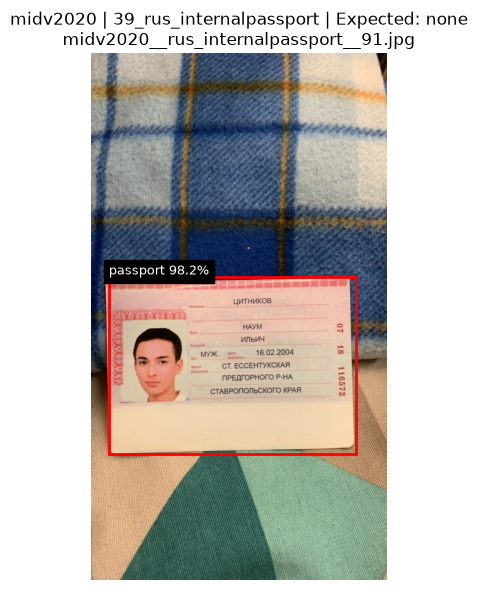

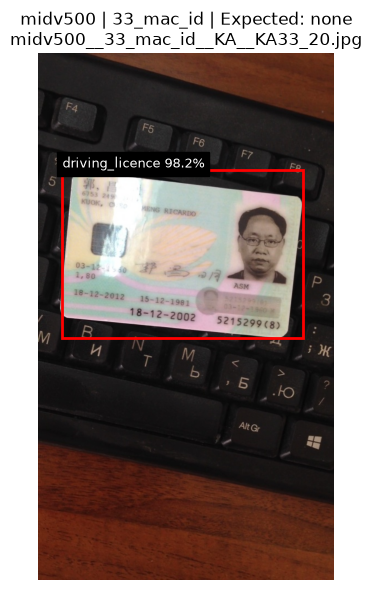

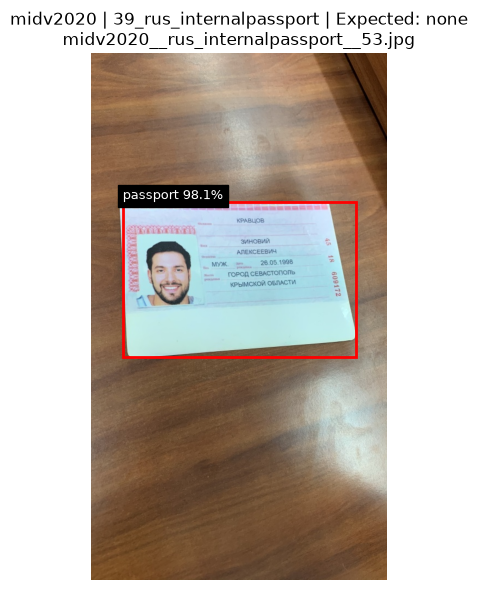

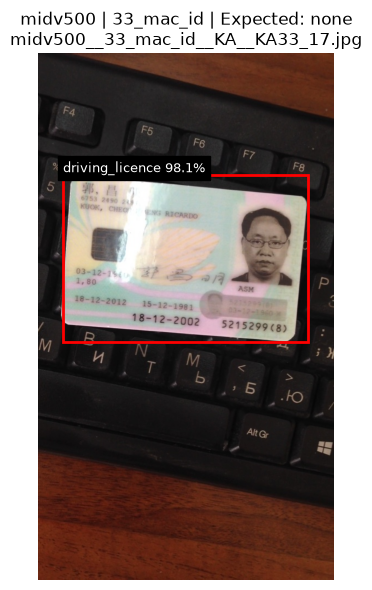

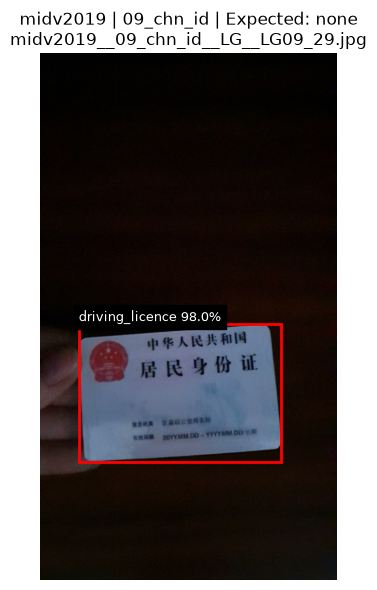

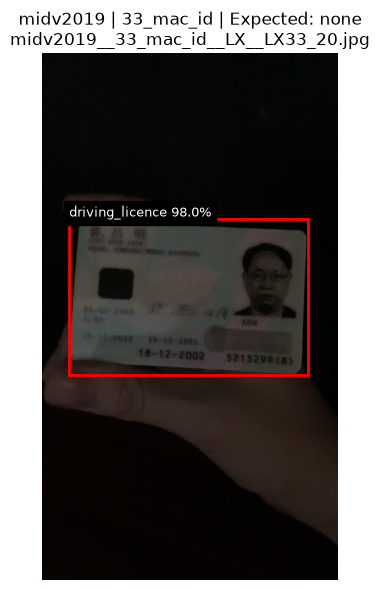

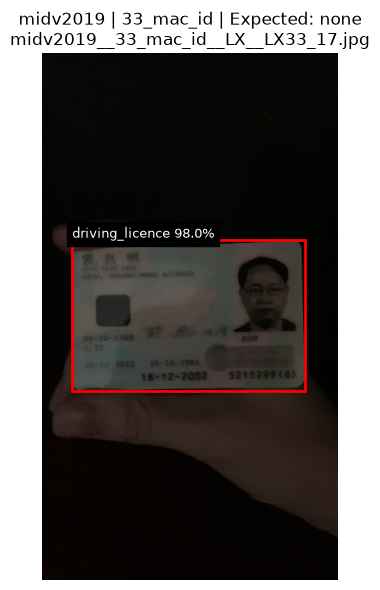

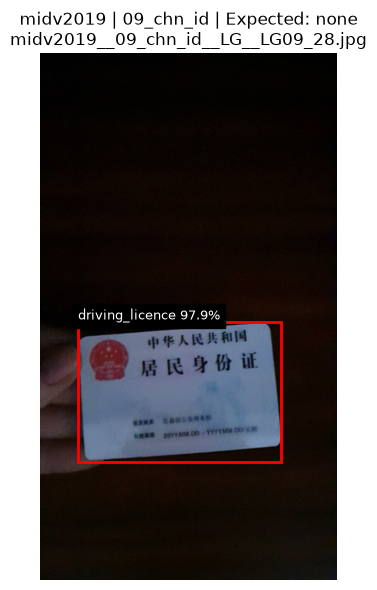

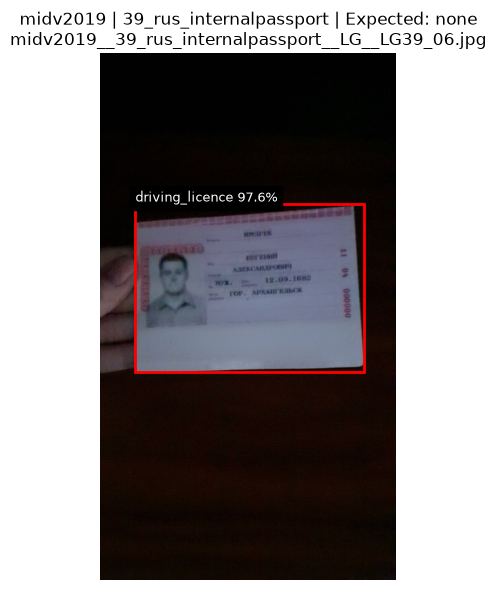

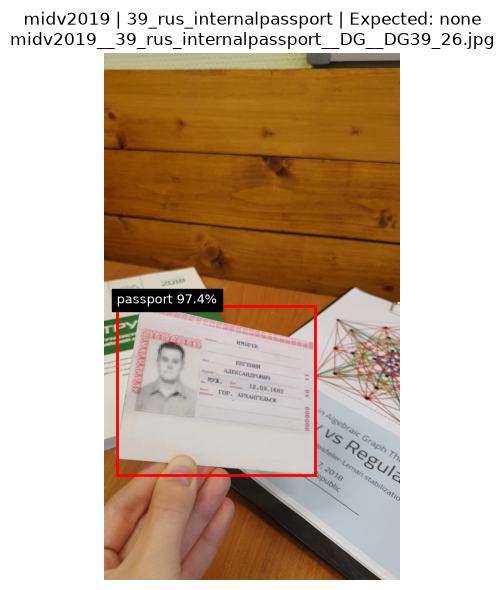

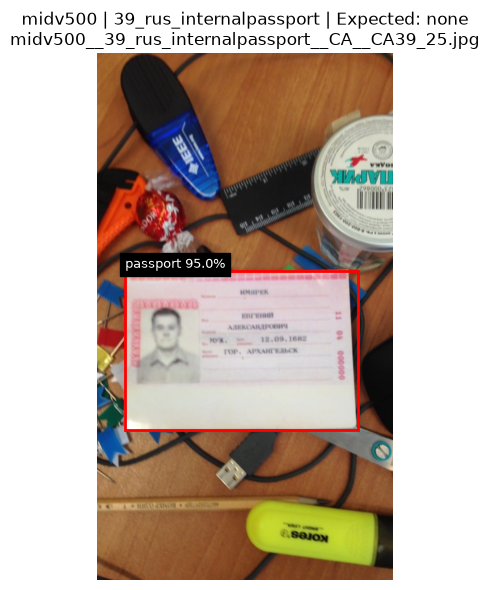

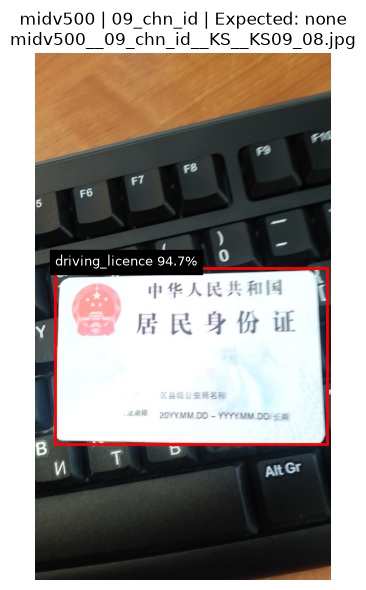

Review the object inside each box and whether the negative label is correct.
Collect similar independent examples for training; keep these validation images out of training.


In [7]:
# Change these controls, then rerun only this cell; inference is not repeated.
SOURCE_FILTER = None       # e.g. "midv2019"
DESIGN_FILTER = None       # copy a design name from the summary table
MAX_IMAGES = 12
PER_DESIGN = 2              # cap per (source, design); increase to see more frames
assert MAX_IMAGES > 0 and PER_DESIGN > 0

negative_gallery = []
negative_displayed = Counter()
for failure in negative_failures:
    record = failure["record"]
    if SOURCE_FILTER is not None and record["source"] != SOURCE_FILTER:
        continue
    if DESIGN_FILTER is not None and record["design"] != DESIGN_FILTER:
        continue
    group = (record["source"], record["design"])
    if negative_displayed[group] >= PER_DESIGN:
        continue
    negative_gallery.append(failure)
    negative_displayed[group] += 1
    if len(negative_gallery) >= MAX_IMAGES:
        break

print(f"Showing {len(negative_gallery)} of {len(negative_failures)} total failure images.")
for failure in negative_gallery:
    record = failure["record"]
    frame = cv2.imread(record["image"])
    if frame is None:
        raise ValueError(f'Cannot read image: {record["image"]}')
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    for x1, y1, x2, y2, score, class_id in failure["detections"]:
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="red", linewidth=2,
        ))
        ax.text(
            x1, max(0, y1 - 5), f"{CLASS_NAMES[int(class_id)]} {score:.1%}",
            color="white", backgroundcolor="black", fontsize=9,
        )
    ax.set_title(
        f'{record["source"]} | {record["design"]} | Expected: none\n'
        f'{Path(record["image"]).name}'
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    del frame

print("Review the object inside each box and whether the negative label is correct.")
print("Collect similar independent examples for training; keep these validation images out of training.")


## Export the 12 reviewed QA samples

Copies only the current 12-image negative_gallery into false_positive_imgs/ at the repository root. Run the preceding gallery with default controls first. Original image bytes are preserved. The manifest records expected none labels, predicted classes, confidence, and boxes. A directory-local ignore exception permits tracking these JPEGs. No staging or commits occur. These validation-derived QA fixtures must stay out of training.

In [8]:
import shutil

assert "negative_gallery" in globals() and len(negative_gallery) == 12, (
    "Run the negative gallery with default filters: 12 images, 2 per design."
)
QA_EXPORT = PROJECT / "false_positive_imgs"
qa_export_rows = []
for failure in negative_gallery:
    record = failure["record"]
    assert record["split"] == "val" and record["class"] is None
    source_path = Path(record["image"])
    relative = Path(record["source"]) / record["design"] / source_path.name
    destination = QA_EXPORT / relative
    image_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        assert hashlib.sha256(destination.read_bytes()).hexdigest() == image_hash, (
            f"Refusing to overwrite a different image: {destination}"
        )
    else:
        shutil.copyfile(source_path, destination)
    qa_export_rows.append({
        "file": relative.as_posix(), "sha256": image_hash,
        "source": record["source"], "design": record["design"],
        "split": "val", "expected": "none",
        "prepared_image": str(source_path), "original_image": record["original"],
        "width": record["width"], "height": record["height"],
        "detections": [
            {"predicted": CLASS_NAMES[int(d[5])], "confidence": float(d[4]),
             "box_xyxy": [float(value) for value in d[:4]]}
            for d in failure["detections"]
        ],
    })
qa_export_manifest = {
    "purpose": "12 reviewed validation false positives for QA; not training data",
    "model": MODEL.relative_to(PROJECT).as_posix(),
    "checkpoint_sha256": detector.contract["checkpoint_sha256"],
    "confidence": detector.confidence, "nms_iou": detector.nms_iou,
    "coordinates": "xyxy pixels in the supplied prepared image",
    "selection": "Gallery: 12 highest-confidence failures, maximum 2 per source/design",
    "scanned_validation_negatives": len(negative_validation),
    "total_validation_failures": len(negative_failures),
    "samples": qa_export_rows,
}
(QA_EXPORT / "manifest.json").write_text(
    json.dumps(qa_export_manifest, indent=2) + "\n", encoding="utf-8"
)
(QA_EXPORT / ".gitignore").write_text(
    "# Permit these QA fixture JPEGs despite parent image ignores.\n!*.jpg\n",
    encoding="utf-8",
)
(QA_EXPORT / "README.md").write_text(
    "# False-positive QA samples\n\n"
    "Twelve reviewed negative validation images incorrectly accepted as a passport or "
    f"driving licence at confidence >= {detector.confidence:.2f}. "
    "Expected result for every image: none.\n\n"
    "Images are grouped by source dataset and document design. See manifest.json "
    "for predicted labels, scores, box coordinates, image hashes and provenance. "
    "Original prepared JPEG bytes are preserved; boxes are metadata, not painted onto images.\n\n"
    "These are validation-derived QA fixtures. Do not add them or other frames of these "
    "held-out designs to training. This selected regression set is not an unbiased benchmark. "
    "Russian internal passports are excluded from the accepted international passport class.\n\n"
    "Reproduce with notebook 11's default negative gallery and export cell. "
    "Source dataset licensing and attribution requirements continue to apply.\n",
    encoding="utf-8",
)
print("Exported QA samples:", len(qa_export_rows), "| Directory:", QA_EXPORT)
print("No Git staging or commit performed.")


Exported QA samples: 12 | Directory: /home/joe/PycharmProjects/id-capture/false_positive_imgs
No Git staging or commit performed.


## Compare failures with existing training coverage

The audit below counts training negatives and checks document-design separation. Exact designs absent from training are intentional under this experiment's unseen-design split. Do not move validation images into training.

The final probe uses only training negatives: up to twelve evenly spaced images per source/design group. It can identify existing training confusions for review. This diagnostic sample is not a full training false-positive rate and does not establish visual similarity. No training or dataset writes occur.

In [9]:
from collections import defaultdict

coverage_records = validation_manifest["records"]
design_splits = defaultdict(set)
for record in coverage_records:
    design_splits[record["design"]].add(record["split"])
assert all(len(splits) == 1 for splits in design_splits.values()), "Design leakage across splits."

training_records = [r for r in coverage_records if r["split"] == "train"]
training_negatives = [r for r in training_records if r["class"] is None]
training_negative_counts = Counter(r["design"] for r in training_negatives)
training_design_counts = Counter(r["design"] for r in training_records)
print(
    f"Training negatives: {len(training_negatives)}/{len(training_records)} "
    f"({len(training_negatives)/len(training_records):.1%}); "
    f"{len(training_negative_counts)} designs include negative images."
)
print("Some target designs include negative frames because the document is fully out of view.")
show_table([
    {
        "Training design": design, "Negative images": count,
        "All training images": training_design_counts[design],
        "Sources": ", ".join(sorted({
            r["source"] for r in training_negatives if r["design"] == design
        })),
    }
    for design, count in sorted(training_negative_counts.items())
])
failed_design_counts = Counter(f["record"]["design"] for f in negative_failures)
validation_design_counts = Counter(r["design"] for r in negative_validation)
confusion_counts = Counter()
for failure in negative_failures:
    for class_id in {int(d[5]) for d in failure["detections"]}:
        confusion_counts[(failure["record"]["design"], CLASS_NAMES[class_id])] += 1
print("Validation failures versus exact-design training coverage:")
show_table([
    {
        "Held-out design": design,
        "Negative validation images": validation_design_counts[design],
        "False-positive images": count,
        "Predicted licence": confusion_counts[(design, "driving_licence")],
        "Predicted passport": confusion_counts[(design, "passport")],
        "Exact-design training images": training_design_counts[design],
    }
    for design, count in failed_design_counts.most_common()
])
print("Class counts can overlap when one image has boxes from both classes.")
print("Exact-design coverage is not a visual-similarity measure.")


Training negatives: 6172/13100 (47.1%); 24 designs include negative images.
Some target designs include negative frames because the document is fully out of view.


Training design,Negative images,All training images,Sources
01_alb_id,520,520,"midv2019, midv2020, midv500"
02_aut_drvlic_new,5,420,midv500
03_aut_id_old,420,420,"midv2019, midv500"
04_aut_id,420,420,"midv2019, midv500"
07_chl_id,420,420,"midv2019, midv500"
08_chn_homereturn,420,420,"midv2019, midv500"
10_cze_id,420,420,"midv2019, midv500"
12_deu_drvlic_new,5,420,midv500
13_deu_drvlic_old,8,420,midv500
14_deu_id_new,420,420,"midv2019, midv500"


Validation failures versus exact-design training coverage:


Held-out design,Negative validation images,False-positive images,Predicted licence,Predicted passport,Exact-design training images
33_mac_id,420,272,118,183,0
39_rus_internalpassport,520,64,16,52,0
09_chn_id,420,48,39,14,0
50_xpo_id,420,5,5,0,0


Class counts can overlap when one image has boxes from both classes.
Exact-design coverage is not a visual-similarity measure.


In [10]:
# Only training negatives are probed. No training or dataset writes occur.
TRAIN_PROBES_PER_GROUP = 12
assert TRAIN_PROBES_PER_GROUP > 0
training_groups = defaultdict(list)
for record in training_negatives:
    training_groups[(record["source"], record["design"])].append(record)
training_probe_records = []
for group, group_records in sorted(training_groups.items()):
    ordered = sorted(group_records, key=lambda r: r["image"])
    indices = np.linspace(
        0, len(ordered) - 1, min(TRAIN_PROBES_PER_GROUP, len(ordered)), dtype=int
    )
    training_probe_records.extend(ordered[int(i)] for i in indices)
training_probe_totals = Counter()
training_probe_hits = Counter()
training_probe_failures = []
probe_started = time.perf_counter()
for index, record in enumerate(training_probe_records, 1):
    frame = cv2.imread(record["image"])
    if frame is None:
        raise ValueError(f'Cannot read training image: {record["image"]}')
    boxes = detector.predict_bgr(frame)
    group = (record["source"], record["design"])
    training_probe_totals[group] += 1
    if len(boxes):
        training_probe_hits[group] += 1
        training_probe_failures.append({
            "record": record, "detections": boxes,
            "top_score": float(boxes[:, 4].max()),
        })
    del frame
    if index == 1 or index % 100 == 0 or index == len(training_probe_records):
        print(
            f"Training-only diagnostic {index}/{len(training_probe_records)} "
            f"| {time.perf_counter() - probe_started:.0f}s elapsed", flush=True,
        )
training_probe_failures.sort(key=lambda f: (-f["top_score"], f["record"]["image"]))
show_table([
    {
        "Source": source, "Training design": design,
        "Sampled negative images": total,
        "Sampled images with detections": training_probe_hits[(source, design)],
    }
    for (source, design), total in sorted(
        training_probe_totals.items(), key=lambda item: (-training_probe_hits[item[0]], item[0])
    )
])
print("Training-negative examples to inspect, ranked by confidence (up to 12):")
show_table([
    {
        "Design": f["record"]["design"],
        "Predicted classes": ", ".join(sorted({
            CLASS_NAMES[int(d[5])] for d in f["detections"]
        })),
        "Top confidence": f'{f["top_score"]:.1%}',
        "Image": f["record"]["image"],
    }
    for f in training_probe_failures[:12]
])
print("Full results: training_probe_failures. No weights or splits changed.")


Training-only diagnostic 1/439 | 0s elapsed
Training-only diagnostic 100/439 | 2s elapsed
Training-only diagnostic 200/439 | 4s elapsed
Training-only diagnostic 300/439 | 7s elapsed
Training-only diagnostic 400/439 | 10s elapsed
Training-only diagnostic 439/439 | 11s elapsed


Source,Training design,Sampled negative images,Sampled images with detections
midv500,04_aut_id,12,1
midv2019,01_alb_id,12,0
midv2019,03_aut_id_old,12,0
midv2019,04_aut_id,12,0
midv2019,07_chl_id,12,0
midv2019,08_chn_homereturn,12,0
midv2019,10_cze_id,12,0
midv2019,14_deu_id_new,12,0
midv2019,15_deu_id_old,12,0
midv2019,20_esp_id_new,12,0


Training-negative examples to inspect, ranked by confidence (up to 12):


Design,Predicted classes,Top confidence,Image
04_aut_id,driving_licence,40.8%,/home/joe/PycharmProjects/id-capture/training/data/yolox_all_sources/images/train/midv500__04_aut_id__PS__PS04_08.jpg


Full results: training_probe_failures. No weights or splits changed.


## Findings from the coverage check

On the reviewed run, 389/2,211 negative validation images produced detections. Macau ID cards accounted for 272 failures, Russian internal passports for 64, Chinese ID cards for 48, and the remaining design for 5. These counts include correlated video frames.

Training already contains 6,172 negative images out of 13,100 images (47.1%). The training-only diagnostic found one false-positive image among 439 sampled negatives. This sample is deliberately spread across source/design groups; it is not an estimate from a random or full training evaluation.

The failing validation designs have no exact-design training examples, by design. Together, these results suggest a generalisation gap to unfamiliar non-target documents; they do not prove its cause.

For the next experiment:
- Prioritise additional independent non-target document designs and capture conditions, particularly cards resembling licences and booklets resembling international passports.
- Review geometric augmentation: the current baseline uses brightness/contrast augmentation only. Test one change at a time, preserving correct box transformations.
- Keep the 12 exported QA fixtures and all existing validation/test designs out of training.
- Choose thresholds on validation and measure both class recalls as well as negative false positives; reject changes that reduce false positives by merely missing more real documents.
- New data is not added and no model is retrained by this audit. The exported fixtures are QA samples only.
